<a href="https://colab.research.google.com/github/mchietino/TP-Delito_en_AMBA-Mica-/blob/Mica/An%C3%A1lisis_socioecon%C3%B3mico_de_CABA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Análisis socioeconómico de CABA (II): condiciones territoriales de las comunas
Esta sección complementa el análisis de las condiciones de vida de los hogares con indicadores del territorio: la presencia de barrios populares, las condiciones habitacionales y educativas relevadas por el Censo 2022 y la estructura comercial (usos del suelo). El objetivo es caracterizar cada comuna para luego relacionar estas condiciones con la frecuencia y el tipo de delitos registrados.


###Condiciones territoriales de las comunas:

Se caracteriza a las 15 comunas de la Ciudad con dos fuentes:
- **Censo Nacional 2022 (INDEC):** cobertura de salud, nivel educativo, desocupación,
  tipo de vivienda y régimen de tenencia.
- **Registro de barrios populares (Gobierno de la Ciudad, BA Data):** cantidad y superficie
  de villas, asentamientos y conjuntos de vivienda social.

Los indicadores se calcularon como porcentajes para que las comunas sean comparables,
y cada barrio popular se asignó a su comuna según su ubicación en el mapa oficial de comunas.

In [38]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [39]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/TP DELITO LABO/territorio_caba_2022.csv")

df = df.rename(columns={
    "pct_sin_obra_social": "% sin obra social",
    "pct_superior_completo": "% con estudios superiores",
    "pct_viviendas_precarias": "% viviendas precarias",
    "pct_alquila": "% que alquila",
    "pct_tenencia_irregular": "% tenencia irregular"
})

df


,comuna,poblacion,% sin obra social,% con estudios superiores,tasa_desocupacion,% viviendas precarias,% que alquila,% tenencia irregular,barrios_populares,barrios_informales,hectareas_barrios
0,1,221001,30.6,32.3,7.9,9.7,46.4,12.4,3,2,80.3
1,2,160609,8.8,53.0,7.0,1.4,38.8,3.5,1,1,1.9
2,3,193537,22.6,30.9,8.3,8.6,47.9,4.7,2,1,1.1
3,4,227024,32.0,21.2,9.0,7.0,33.3,16.1,33,14,151.8
4,5,192449,14.3,37.3,7.2,4.2,40.0,4.3,1,0,1.1
5,6,201764,9.5,43.9,6.8,2.4,33.8,3.7,2,2,0.7
6,7,213262,19.9,32.7,7.9,4.3,33.1,6.1,13,2,87.9
7,8,203888,46.1,12.0,10.3,5.5,24.9,21.1,44,21,327.3
8,9,167908,25.2,23.9,8.6,2.5,29.7,8.9,10,4,49.8
9,10,171896,17.0,31.3,7.6,2.5,30.2,5.3,3,0,3.0


**Diccionario de variables** (una fila por comuna, año 2022)

- `comuna`: número de comuna (1 a 15).
- `poblacion`: habitantes de la comuna.
- `% sin obra social`: población sin obra social ni prepaga.
- `% con estudios superiores`: personas de 25 años o más con estudios terciarios, universitarios o de posgrado completos.
- `tasa_desocupacion`: porcentaje de desocupados sobre la población económicamente activa.
- `% viviendas precarias`: viviendas que son rancho, casilla, pieza de inquilinato, local no habitacional o vivienda móvil.
- `% que alquila`: población que vive en una vivienda alquilada.
- `% tenencia irregular`: población que vive en una vivienda propia sin documentación o en otra situación irregular.
- `barrios_populares`: cantidad de barrios populares (villas, asentamientos y vivienda social).
- `barrios_informales`: cantidad de villas, asentamientos y núcleos habitacionales transitorios.
- `hectareas_barrios`: superficie total que ocupan los barrios populares, en hectáreas.

*Fuentes: Censo Nacional 2022 (INDEC) y registro de barrios populares (BA Data).*

**Resultados:**

Las condiciones territoriales de la Ciudad muestran una fuerte división entre el norte y el sur.

- **Comuna 8 (Villa Lugano, Villa Soldati, Villa Riachuelo):** es la más vulnerable en casi todos
  los indicadores. El 46,1% de su población no tiene obra social ni prepaga, solo el 12,0% de los
  mayores de 25 años completó estudios superiores, tiene la desocupación más alta (10,3%) y el 21,1%
  vive en una situación de tenencia irregular. Concentra 44 de los 132 barrios populares
  (327 hectáreas, el 43% de su superficie total en la Ciudad).
- **Comunas 13 y 14 (Belgrano, Núñez, Colegiales y Palermo) y Comuna 2 (Recoleta):** están en el
  extremo opuesto. Menos del 9% de su población depende solo del sistema público y más del 52%
  de los adultos tiene estudios superiores completos, más de cuatro veces que en la Comuna 8.
- **Comuna 4 (La Boca, Barracas, Parque Patricios, Nueva Pompeya):** es la segunda en barrios
  populares (33 barrios, 152 hectáreas) y también tiene niveles altos de tenencia irregular (16,1%).
- **Comuna 1 (Retiro, San Nicolás, Puerto Madero, San Telmo, Monserrat, Constitución):** combina
  zonas de alto valor con el Barrio Padre Mugica (ex Villa 31). Tiene el mayor porcentaje de
  viviendas precarias de la Ciudad (9,7%), por la cantidad de piezas en inquilinatos y hoteles.

**Limitación:** el censo clasifica muchas viviendas de los barrios populares como "casa" o
"departamento", por lo que el porcentaje de viviendas precarias subestima la precariedad
en comunas como la 8. Por eso conviene leerlo junto con el registro de barrios populares.

###Estructura comercial de las comunas

Dentro de la investigación queremos relacionar el delito con la estructura comercial del territorio.
Para medirla se usa el **Relevamiento de Usos del Suelo 2022-2024** del Gobierno de la Ciudad (BA Data),
que registra el uso de cada parcela de la Ciudad: vivienda, comercio, oficinas, industria, etc.,
y si se encontraba activa o inactiva al momento del relevamiento.

A partir de este registro se calculan tres indicadores por comuna:
- **Locales comerciales activos:** cantidad de locales en funcionamiento (incluye galerías, shoppings y mercados).
- **% de locales vacíos:** proporción de locales comerciales inactivos. Es un indicador del dinamismo
  o del deterioro de la actividad económica de la zona.
- **Oficinas:** cantidad de parcelas con uso de oficinas en actividad.

El relevamiento informa el barrio de cada parcela, pero no la comuna. Por eso, primero se asigna
cada barrio a su comuna según la división oficial de la Ciudad, y luego se suman los datos por comuna
para incorporarlos a la tabla general.

In [40]:
usos = pd.read_csv("/content/drive/MyDrive/TP DELITO LABO/relevamiento-usos-del-suelo-2022-2024.csv",
                   low_memory=False)

print(usos.shape)
usos[["BARRIO", "TIPO1", "TIPO2", "ESTADO", "AÑO"]].head()

(417764, 14)


,BARRIO,TIPO1,TIPO2,ESTADO,AÑO
0,BELGRANO,GARAGE COMERCIAL,NaN,ACTIVO,2023
1,BELGRANO,UNICOMERCIAL,OPTICA,ACTIVO,2023
2,BELGRANO,RESIDENCIAL,MULTIFAMILIAR,ACTIVO,2023
3,BELGRANO,RESIDENCIAL,MULTIFAMILIAR,ACTIVO,2023
4,BELGRANO,RESIDENCIAL,MULTIFAMILIAR,ACTIVO,2023


In [41]:
print("Valores vacíos por columna:")
print(usos[["BARRIO", "TIPO1", "TIPO2", "ESTADO", "AÑO"]].isna().sum())

print("\nUsos con ESTADO vacío:")
print(usos[usos["ESTADO"].isna()]["TIPO1"].value_counts())

comercios_check = usos[usos["TIPO1"].isin(["UNICOMERCIAL", "MULTICOMERCIAL"])]
print("\nRegistros comerciales:", len(comercios_check))
print("Registros comerciales con ESTADO vacío:", comercios_check["ESTADO"].isna().sum())

Valores vacíos por columna:
BARRIO        0
TIPO1         0
TIPO2     15637
ESTADO    10238
AÑO           0
dtype: int64

Usos con ESTADO vacío:
TIPO1
OBRA EN CONSTRUCCION    4375
BARRIO POPULAR          2678
ESPACIOS VERDES         1722
LOTE                    1091
VIA PUBLICA              372
Name: count, dtype: int64

Registros comerciales: 106966
Registros comerciales con ESTADO vacío: 0


**Valores faltantes:** el archivo tiene valores vacíos en las columnas TIPO2 (uso específico, 15.637 registros)
y ESTADO (activo o inactivo, 10.238 registros). Todos corresponden a usos en los que esas categorías
no aplican, como obras en construcción, lotes, espacios verdes, barrios populares y vía pública.

Los 106.966 registros comerciales, que son los que se usan en este análisis, no presentan valores faltantes.
Por lo tanto, no es necesario eliminar ni completar datos: los vacíos no afectan los indicadores calculados.

In [42]:
barrios_por_comuna = {      # lista qué barrios forman cada comuna, escritos igual que en el archivo (en mayúsculas y sin tildes, salvo la Ñ de Núñez)
    1: ["RETIRO", "SAN NICOLAS", "PUERTO MADERO", "SAN TELMO", "MONSERRAT", "CONSTITUCION"],
    2: ["RECOLETA"],
    3: ["BALVANERA", "SAN CRISTOBAL"],
    4: ["LA BOCA", "BARRACAS", "PARQUE PATRICIOS", "NUEVA POMPEYA"],
    5: ["ALMAGRO", "BOEDO"],
    6: ["CABALLITO"],
    7: ["FLORES", "PARQUE CHACABUCO"],
    8: ["VILLA SOLDATI", "VILLA RIACHUELO", "VILLA LUGANO"],
    9: ["LINIERS", "MATADEROS", "PARQUE AVELLANEDA"],
    10: ["VILLA REAL", "MONTE CASTRO", "VERSALLES", "FLORESTA", "VELEZ SARSFIELD", "VILLA LURO"],
    11: ["VILLA GRAL. MITRE", "VILLA DEVOTO", "VILLA DEL PARQUE", "VILLA SANTA RITA"],
    12: ["COGHLAN", "SAAVEDRA", "VILLA URQUIZA", "VILLA PUEYRREDON"],
    13: ["NUÑEZ", "BELGRANO", "COLEGIALES"],
    14: ["PALERMO"],
    15: ["CHACARITA", "VILLA CRESPO", "PATERNAL", "VILLA ORTUZAR", "AGRONOMIA", "PARQUE CHAS"]
}

mapa = {barrio: comuna for comuna, barrios in barrios_por_comuna.items() for barrio in barrios}   # “da vuelta” esa lista para tener, para cada barrio, su comuna

usos["comuna"] = usos["BARRIO"].map(mapa)   # busca el barrio de cada fila en ese mapa y le asigna su comuna
print("Registros sin comuna:", usos["comuna"].isna().sum())

Registros sin comuna: 0


**Asignación de comunas:** cada uno de los 48 barrios oficiales pertenece siempre a la misma comuna.
Se arma esa correspondencia y se agrega la comuna a cada registro.

**Cálculo de los indicadores:** se seleccionan los registros comerciales (locales individuales y
espacios multicomerciales) y se cuentan por comuna los activos y los inactivos.
También se cuentan las oficinas en actividad.

In [43]:
comercios = usos[usos["TIPO1"].isin(["UNICOMERCIAL", "MULTICOMERCIAL"])]
oficinas = usos[(usos["TIPO1"] == "OFICINAS") & (usos["ESTADO"] == "ACTIVO")]

comercial = pd.DataFrame({
    "locales_comerciales": comercios[comercios["ESTADO"] == "ACTIVO"].groupby("comuna").size(),
    "locales_inactivos": comercios[comercios["ESTADO"] == "INACTIVO"].groupby("comuna").size(),
    "locales_total": comercios.groupby("comuna").size(),
    "oficinas": oficinas.groupby("comuna").size()
}).reset_index()

comercial["% locales vacíos"] = (comercial["locales_inactivos"] / comercial["locales_total"] * 100).round(1)

comercial = comercial[["comuna", "locales_comerciales", "% locales vacíos", "oficinas"]]
comercial

,comuna,locales_comerciales,% locales vacíos,oficinas
0,1,8856,21.3,1833
1,2,4327,8.5,142
2,3,8277,14.5,326
3,4,4774,29.3,267
4,5,4875,18.1,200
5,6,3996,11.3,55
6,7,6344,18.3,158
7,8,2947,23.6,50
8,9,5731,20.6,148
9,10,6566,20.4,225


**Incorporación a la tabla general:** se agregan los tres indicadores comerciales
a la tabla de cada comuna, usando el número de comuna como referencia.

In [44]:
df = df.merge(comercial, on="comuna")

df.head()

,comuna,poblacion,% sin obra social,% con estudios superiores,tasa_desocupacion,% viviendas precarias,% que alquila,% tenencia irregular,barrios_populares,barrios_informales,hectareas_barrios,locales_comerciales,% locales vacíos,oficinas
0,1,221001,30.6,32.3,7.9,9.7,46.4,12.4,3,2,80.3,8856,21.3,1833
1,2,160609,8.8,53.0,7.0,1.4,38.8,3.5,1,1,1.9,4327,8.5,142
2,3,193537,22.6,30.9,8.3,8.6,47.9,4.7,2,1,1.1,8277,14.5,326
3,4,227024,32.0,21.2,9.0,7.0,33.3,16.1,33,14,151.8,4774,29.3,267
4,5,192449,14.3,37.3,7.2,4.2,40.0,4.3,1,0,1.1,4875,18.1,200


In [45]:
# 1. Superficie de barrios populares cada 1.000 habitantes
df["ha_cada_1000_hab"] = df["hectareas_barrios"] / df["poblacion"] * 1000

# 2. Locales comerciales cada 1.000 habitantes
df["locales_cada_1000_hab"] = df["locales_comerciales"] / df["poblacion"] * 1000

# 3. Zona de la Ciudad
zonas = {1: "Centro", 2: "Norte", 3: "Centro", 4: "Sur", 5: "Centro",
         6: "Centro", 7: "Centro", 8: "Sur", 9: "Sur", 10: "Centro",
         11: "Norte", 12: "Norte", 13: "Norte", 14: "Norte", 15: "Centro"}
df["zona"] = df["comuna"].map(zonas)

df.groupby("zona")[["% sin obra social", "% con estudios superiores", "barrios_populares",
                    "locales_cada_1000_hab", "% locales vacíos"]].mean().round(1)

,% sin obra social,% con estudios superiores,barrios_populares,locales_cada_1000_hab,% locales vacíos
zona,,,,,
Centro,18.5,35.2,4.7,33.2,17.7
Norte,9.4,47.2,2.4,25.6,13.9
Sur,34.4,19.0,29.0,23.2,24.5


### Comparación por zona

El gráfico compara cuatro indicadores representativos de las dimensiones analizadas
(salud, educación, vivienda y actividad comercial) entre las zonas norte, centro y sur
de la Ciudad. Cada barra muestra el promedio de las comunas de cada zona.

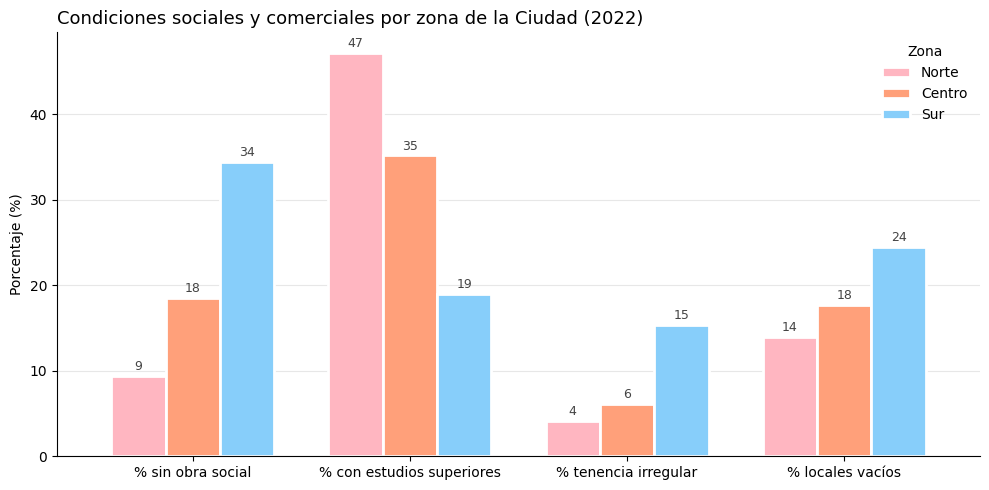

In [48]:
import matplotlib.pyplot as plt

# 1. Variables a comparar y promedio por zona
variables = ["% sin obra social", "% con estudios superiores", "% tenencia irregular", "% locales vacíos"]
por_zona = df.groupby("zona")[variables].mean().loc[["Norte", "Centro", "Sur"]]

# 2. Gráfico de barras agrupadas
colores = ["#FFB6C1", "#FFA07A", "#87CEFA"]
ax = por_zona.T.plot(kind="bar", color=colores, width=0.75, edgecolor="white", linewidth=2, figsize=(10, 5))

# 3. Valores arriba de cada barra
for barras in ax.containers:
    ax.bar_label(barras, fmt="%.0f", fontsize=9, color="#444444", padding=2)

# 4. Títulos y formato
ax.set_title("Condiciones sociales y comerciales por zona de la Ciudad (2022)", fontsize=13, loc="left")
ax.set_ylabel("Porcentaje (%)")
ax.set_xlabel("")
ax.set_xticklabels(por_zona.columns, rotation=0)
ax.legend(title="Zona", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Una Ciudad, tres realidades

El gráfico muestra que, en los cuatro indicadores, la situación empeora de norte a sur.

**Condiciones sociales:** la población sin obra social casi se cuadruplica entre el norte (9%) y el sur (34%),
y la proporción de adultos con estudios superiores en el norte (47%) duplica a la del sur (19%).
La tenencia irregular de la vivienda, casi inexistente en el norte (4%), alcanza el 15% en el sur,
donde además se concentran 87 de los 132 barrios populares de la Ciudad.

**Actividad comercial:** uno de cada cuatro locales del sur está vacío (24%), frente al 14% del norte.
Sin embargo, la mayor densidad comercial no está en el norte sino en el centro, con 33 locales
cada 1.000 habitantes, por la presencia de grandes ejes comerciales como Once, Flores y el microcentro.

**Síntesis:** la desigualdad no es una división entre dos extremos, sino un gradiente que avanza
de norte a sur. El sur combina peores condiciones sociales, más barrios populares y una actividad
comercial más débil; el norte reúne las mejores condiciones, y el centro se distingue como el
principal polo comercial de la Ciudad. Estas diferencias son el punto de partida para analizar
si la frecuencia y el tipo de delitos también varían entre zonas.